In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.regularizers import l2

import warnings
warnings.filterwarnings('ignore')

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_worst  area_wor

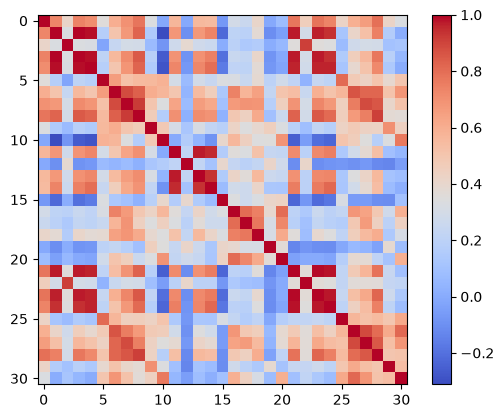

In [2]:
df = pd.read_csv('code_2_wisconsin_breast_cancer_data.csv') # loads dataset to pandas

print(df.head()) # print 5 first rows of data
print(df.info()) # checls datatypes and null values

if 'id' in df.columns: # drops ID colum
    df = df.drop(columns=['id'])

df['diagnosis'] = df['diagnosis'].astype(str).str.strip() # got an error and gemini gave me this to fix it. 
df['diagnosis'] = df['diagnosis'].map({'M':1, 'B':0})

df = df.dropna() # drops missing values

print(df['diagnosis'].value_counts()) # checks c;ass balance 

plt.imshow(df.corr(),cmap='coolwarm') # heatmap to see wich features are correlated
plt.colorbar()
plt.show()

X = df.drop(columns=['diagnosis']).astype(float) # seperates dependent and independedn variables
y = df['diagnosis'].astype(float)

X_train, X_test, y_train, y_test = train_test_split( # 80/20 train/test split with stratification
    X, y, test_size=0.2, random_state=50, stratify=y
)

scaler = StandardScaler() # scale features using StandardScaler
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [3]:
model = keras.Sequential([
    keras.layers.Dense(64,activation='relu',kernel_regularizer=keras.regularizers.l2(0.001), input_shape=(X_train_scaled.shape[1],)), # fist dense hidden layer
    keras.layers.Dropout(0.3), # dropout layer
    keras.layers.Dense(32,activation='relu',kernel_regularizer=keras.regularizers.l2(0.001)), # second hidden layer
    keras.layers.Dropout(0.3), # dropout layer
    keras.layers.Dense(1,activation='sigmoid') # output layer for binary classification 
])

model.compile(
    optimizer='adam', # compiles model using adam
    loss='binary_crossentropy', # sets binary crossentropy loss function
    metrics=['accuracy'] # tracks accuracy
)

history = model.fit( 
    X_train_scaled, y_train.values, # trains model on scaled training data
    validation_split=0.2, # 20% for validation
    epochs=50, # trains for 50 epocjs
    batch_size=32, # sets batch size to 32
    verbose=0
)

print(f"Training Loss: {history.history['loss'][-1]:.4f} - Training Accuracy: {history.history['accuracy'][-1]:.4f}") # prints last epoch training loss and accuracy
print(f"Validation Loss: {history.history['val_loss'][-1]:.4f} - Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}") # prints last epochs validation loss and accuracy

nn_test_loss, nn_test_acc = model.evaluate(X_test_scaled, y_test.values, verbose=0) # evaluates model on test set

print(f"Test Loss: {nn_test_loss:.4f} - Test Accuracy: {nn_test_acc:.4f}") # prints test loss and acuracy 

nn_test_prob = model.predict(X_test_scaled).ravel() # gets predicted probabilities for the test set
nn_roc_auc = roc_auc_score(y_test, nn_test_prob) # calculates ROC AUC score
print(f"Neural Network ROC AUC Score: {nn_roc_auc:.4f}") # prints ROC AUC score

Training Loss: 0.0782 - Training Accuracy: 0.9918
Validation Loss: 0.0992 - Validation Accuracy: 0.9780
Test Loss: 0.1750 - Test Accuracy: 0.9649
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Neural Network ROC AUC Score: 0.9940


Train Accuracy: 0.9934
Test Accuracy: 0.9825
Test ROC AUC Score: 0.9960


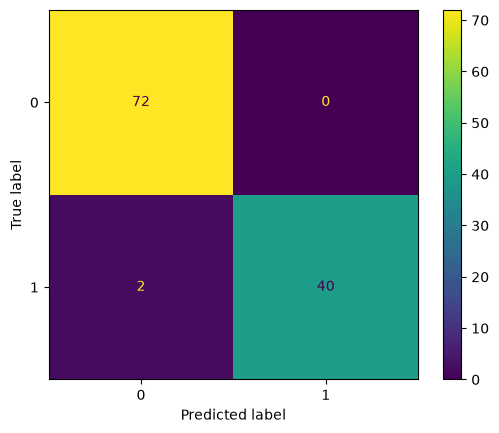

In [4]:
pipe_logreg = Pipeline([ # pipeline that scales features and fits logistic regression model
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state=50))
])

pipe_logreg.fit(X_train, y_train) # trains the model

y_train_predict = pipe_logreg.predict(X_train) # predict train and test sets
y_test_predict = pipe_logreg.predict(X_test)

train_acc = accuracy_score(y_train, y_train_predict) # calculate and print train and test accuracy
test_acc = accuracy_score(y_test, y_test_predict)
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

roc_auc = roc_auc_score(y_test, pipe_logreg.predict_proba(X_test)[:,1]) # calculate and print ROC AUC score
print(f"Test ROC AUC Score: {roc_auc:.4f}")

cm = confusion_matrix(y_test, y_test_predict) # plot confusion matrix
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_display.plot()
plt.show()


In [5]:
print("Neural Network vs Logistic Regression")
print(f"Accuracy: {nn_test_acc:.4f} vs {test_acc:.4f}")
print(f"ROC AUC: {nn_roc_auc:.4f} vs {roc_auc:.4f}")

Neural Network vs Logistic Regression
Accuracy: 0.9649 vs 0.9825
ROC AUC: 0.9940 vs 0.9960
